In [1]:
from sklearn.datasets import make_blobs
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

In [2]:
RANDOM_STATE = 42

In [3]:
X, y = make_blobs(
    n_samples=500,
    n_features=2,
    centers=8,
    cluster_std=1.5,
    random_state=RANDOM_STATE
)

In [4]:
df = pd.DataFrame(X, columns=['X1', 'X2'])
df['y'] = y

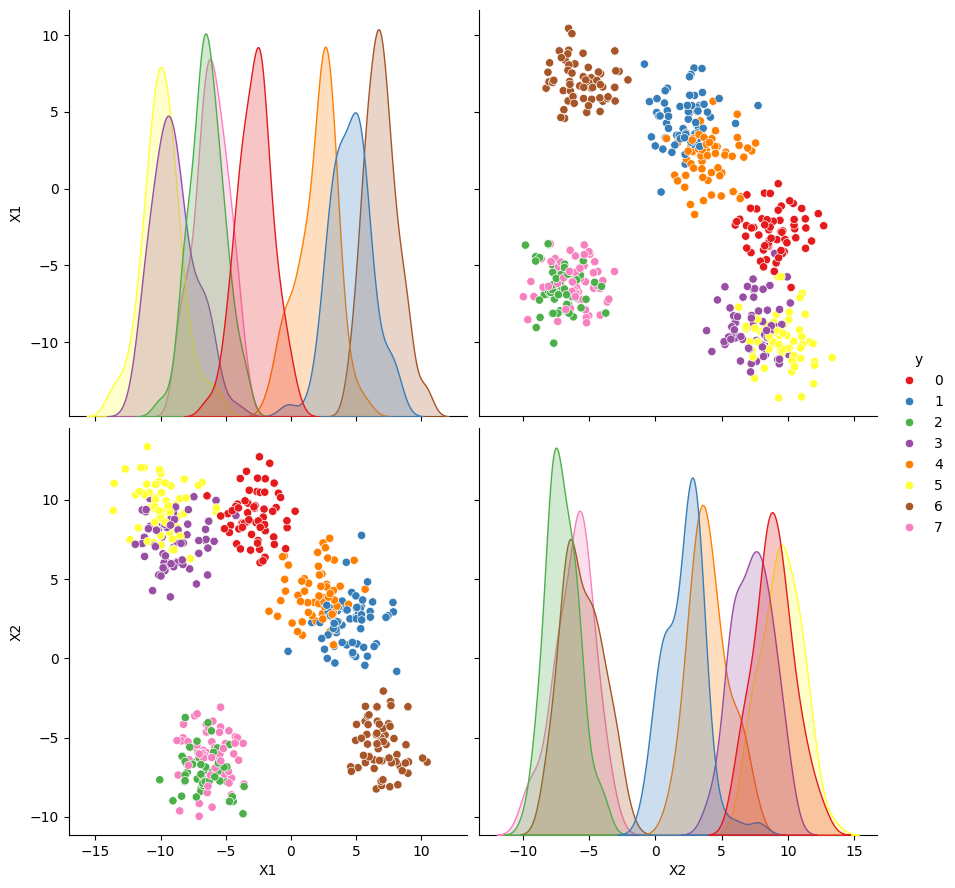

In [5]:
sns.pairplot(df, hue='y', palette="Set1", height=4.5)

In [6]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    random_state=RANDOM_STATE,
    test_size=0.25
)

In [7]:
from sklearn.neural_network import MLPClassifier

models = []

for alpha in [0.01, 0.1, 1.0, 5.0, 20]:
    for hidden_size in [(10,), (10, 10), (10, 10, 10)]:
        clf = MLPClassifier(
            solver='lbfgs',
            alpha = alpha,
            hidden_layer_sizes=hidden_size,
            random_state=RANDOM_STATE,
            max_iter=100000,
            early_stopping=True,
        )
        clf.fit(X_train, y_train)
        models.append(clf)

In [8]:
from sklearn.metrics import f1_score

print(f"{'alpha':<20}{'layer size':<20}{'f1':<20}")

data = []

for clf in models:
    f1_value = f1_score(y_test, clf.predict(X_test), average="macro")
    data.append((clf.alpha, str(clf.hidden_layer_sizes), f1_value))

for alpha, layer_size, f1 in sorted(data, key=lambda x: x[2], reverse=True):
    print(f"{alpha:<20}{layer_size:<20}{f1:<20}")


alpha               layer size          f1                  
0.1                 (10,)               0.8241377610329224  
0.01                (10, 10)            0.8235950439460876  
0.1                 (10, 10, 10)        0.8171130952380952  
20                  (10,)               0.8093164881471333  
20                  (10, 10)            0.8009672619047619  
1.0                 (10, 10, 10)        0.8000352443609022  
1.0                 (10,)               0.7996406345961407  
0.01                (10,)               0.7979655003836068  
1.0                 (10, 10)            0.7973754951895868  
5.0                 (10,)               0.7910320187360036  
5.0                 (10, 10)            0.7902075382645899  
0.01                (10, 10, 10)        0.7863150344134117  
5.0                 (10, 10, 10)        0.7851901440611118  
0.1                 (10, 10)            0.775487504026524   
20                  (10, 10, 10)        0.77401109103366    
